# Spatial Join: DC Crime Points → Census Tracts

Count crime points inside each census tract and add the counts to the polygon data.
Data are already downloaded and extracted:

```text
spatial_join_dc/
├── DC_Crime_CensusTract_SpatialJoin.ipynb
└── data/
    ├── crime_2025.csv
    └── tracts_2020/
        ├── Census_Tracts_in_2020.shp
        ├── Census_Tracts_in_2020.shx
        ├── Census_Tracts_in_2020.dbf
        └── Census_Tracts_in_2020.prj
```

Sources: [2025 crime records](https://catalog.data.gov/dataset/crime-incidents-in-2025),
[2020 census tracts](https://catalog.data.gov/dataset/census-tracts-in-2020).



> 1. **Tract file:** also keeps `POP100`, `HU100`, `ALAND`.
> 2. **Section 3b (added):** cleaning and feature rules from `Aggregated_Dataset.ipynb` (duplicates, Eastern time, 2025 only, violent/gun flags, daytime/evening/midnight, weekend, reported-within-1-day).
> 3. **Section 7b (added):** contains per-tract shares, computed after the spatial join and grouped by tract `GEOID`.
> 4. **Sections 7c–7e (added):** alcohol licenses and Metro entrances joined to the same tracts, then checks.
> 5. **Section 9:** shapefile column names shortened (10-character limit) and an Excel copy added.
>
> **Why the shares are grouped by `GEOID`, not by the crime file's `CENSUS_TRACT`:** the spatial join puts crime, alcohol licenses, and Metro entrances on the same 2020 tract polygons. The crime file's own `CENSUS_TRACT` code agrees with those polygons for only about 83% of incidents, so mixing the two would combine different geographies.

## 1. Import packages

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Read the tract polygons and convert to EPSG:4326
Keep the shapefile companion files together. `to_crs()` transforms the polygon coordinates.

In [ ]:
tracts = gpd.read_file('data/tracts_2020/Census_Tracts_in_2020.shp')
# ALTERED: also keep POP100, HU100, ALAND (2020 population, housing units, land area)
tracts = tracts[['GEOID', 'TRACT', 'NAME', 'POP100', 'HU100', 'ALAND', 'geometry']].copy()
tracts = tracts.to_crs('EPSG:4326')

tracts.head()

,GEOID,TRACT,NAME,POP100,HU100,ALAND,geometry
0,11001002002,002002,Census Tract 20.02,4072,1532,849376,"POLYGON ((-77.03642 38.94975, -77.03642 38.950..."
1,11001002101,002101,Census Tract 21.01,5687,2335,600992,"POLYGON ((-77.02824 38.95813, -77.02824 38.958..."
2,11001002102,002102,Census Tract 21.02,5099,2221,725975,"POLYGON ((-77.01997 38.95819, -77.01997 38.958..."
3,11001002201,002201,Census Tract 22.01,3485,1229,415173,"POLYGON ((-77.02743 38.95188, -77.02727 38.951..."
4,11001002202,002202,Census Tract 22.02,3339,1454,698895,"POLYGON ((-77.01968 38.95209, -77.01958 38.952..."


## 3. Read the crime CSV
Remove rows without longitude or latitude before creating points.

In [3]:
crime = pd.read_csv('data/crime_2025.csv')
crime = crime.dropna(subset=['LONGITUDE', 'LATITUDE'])

crime[['OFFENSE', 'LONGITUDE', 'LATITUDE']].head()

,OFFENSE,LONGITUDE,LATITUDE
0,SEX ABUSE,-76.976246,38.884077
1,ASSAULT W/DANGEROUS WEAPON,-76.976246,38.884077
2,HOMICIDE,-76.976246,38.884077
3,THEFT F/AUTO,-76.952663,38.920536
4,THEFT/OTHER,-76.952663,38.920536


## 3b. ▲ NEW: Clean the incidents and derive features (our partner's rules)
Taken from `Aggregated_Dataset.ipynb`. The one step **not** carried over is `dropna(subset=['CENSUS_TRACT'])`: the spatial join assigns each incident to a tract from its coordinates, so the crime file's tract code is not needed (the rows without it are kept if they have coordinates).

* Drop duplicates (same `CCN`, `OFFENSE`, and `START_DATE`).
* Convert timestamps from UTC to Eastern time; keep incidents that **started** in 2025.
* `reported_within_1_day`: reported 0 to 1 day after the start. Used only for the time-of-day and weekend shares, because a late report makes the start time unreliable.
* `time_of_day`: daytime 07:00–14:59, evening 15:00–22:59, midnight 23:00–06:59.

In [4]:
crime = crime.drop_duplicates(subset=['CCN', 'OFFENSE', 'START_DATE'])

crime['start'] = pd.to_datetime(crime['START_DATE'], utc=True).dt.tz_convert('America/New_York')
crime = crime[crime['start'].dt.year == 2025].copy()
print('Incidents after cleaning:', len(crime))

crime['report'] = pd.to_datetime(crime['REPORT_DAT'], utc=True).dt.tz_convert('America/New_York')
delay_days = (crime['report'] - crime['start']).dt.total_seconds() / 86400
crime['reported_within_1_day'] = (delay_days >= 0) & (delay_days <= 1)

violent = ['HOMICIDE', 'SEX ABUSE', 'ROBBERY', 'ASSAULT W/DANGEROUS WEAPON']
crime['is_violent'] = crime['OFFENSE'].isin(violent)
crime['is_gun'] = crime['METHOD'] == 'GUN'

hour = crime['start'].dt.hour
crime['time_of_day'] = 'evening'                                   # 15:00-22:59
crime.loc[hour.between(7, 14), 'time_of_day'] = 'daytime'          # 07:00-14:59
crime.loc[(hour >= 23) | (hour <= 6), 'time_of_day'] = 'midnight'  # 23:00-06:59

crime['is_weekend'] = crime['start'].dt.dayofweek >= 5             # Saturday = 5, Sunday = 6

crime[['OFFENSE', 'start', 'time_of_day', 'is_violent', 'reported_within_1_day']].head()

Incidents after cleaning: 23937


,OFFENSE,start,time_of_day,is_violent,reported_within_1_day
0,SEX ABUSE,2025-01-03 18:30:00-05:00,evening,True,True
1,ASSAULT W/DANGEROUS WEAPON,2025-08-28 17:10:00-04:00,evening,True,True
2,HOMICIDE,2025-05-12 14:30:00-04:00,daytime,True,False
3,THEFT F/AUTO,2025-04-26 11:50:00-04:00,daytime,False,False
4,THEFT/OTHER,2025-06-30 13:45:00-04:00,daytime,False,True


## 4. Convert longitude and latitude into points
Longitude is x, latitude is y. The published longitude/latitude values are in EPSG:4326,
so we assign that CRS when creating the geometry.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

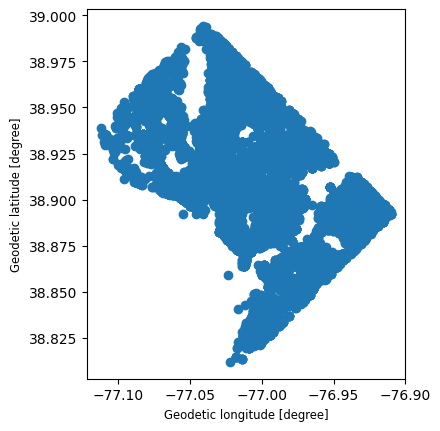

In [5]:
crime_points = gpd.GeoDataFrame(
    crime,
    geometry=gpd.points_from_xy(crime['LONGITUDE'], crime['LATITUDE']),
    crs='EPSG:4326'
)
crime_points.plot()

## 5. Spatial join: assign each matched point to a tract
`within` selects points inside a polygon. `inner` excludes unmatched points.
Points exactly on a boundary are also excluded. This example assumes nonoverlapping
tract polygons, so a point is counted in at most one tract.

In [6]:
joined = gpd.sjoin(
    crime_points,
    tracts[['GEOID', 'geometry']],
    how='inner',
    predicate='within'
)

joined[['OFFENSE', 'GEOID']].head()

,OFFENSE,GEOID
0,SEX ABUSE,11001006804
1,ASSAULT W/DANGEROUS WEAPON,11001006804
2,HOMICIDE,11001006804
3,THEFT F/AUTO,11001009000
4,THEFT/OTHER,11001009000


## 6. Count points by tract and attach the counts to polygons
`size()` counts matched records in each tract. A left attribute merge retains all
tract polygons; tracts with no matched records receive zero.

In [7]:
crime_counts = joined.groupby('GEOID').size()
crime_counts = crime_counts.reset_index(name='crime_n')

tracts_with_crime = tracts.merge(crime_counts, on='GEOID', how='left')
tracts_with_crime['crime_n'] = tracts_with_crime['crime_n'].fillna(0).astype(int)

tracts_with_crime[['GEOID', 'NAME', 'crime_n']].head()

,GEOID,NAME,crime_n
0,11001002002,Census Tract 20.02,85
1,11001002101,Census Tract 21.01,173
2,11001002102,Census Tract 21.02,102
3,11001002201,Census Tract 22.01,54
4,11001002202,Census Tract 22.02,76


## 7. Add counts for each offense type
Use a cross-tabulation: one row per tract, one column per `OFFENSE` category.
Each cell contains the number of matched records of that type in that tract.
If a record has a missing offense type, keep it in an `UNKNOWN` category so it is not
lost from the type totals.

In [8]:
offense_counts = pd.crosstab(
    joined['GEOID'],
    joined['OFFENSE'].fillna('UNKNOWN')
)

offense_counts.head()

OFFENSE,ARSON,ASSAULT W/DANGEROUS WEAPON,BURGLARY,HOMICIDE,MOTOR VEHICLE THEFT,ROBBERY,SEX ABUSE,THEFT F/AUTO,THEFT/OTHER
GEOID,,,,,,,,,
11001000101,0,0,0,0,1,1,0,5,10
11001000102,0,0,1,0,17,1,1,64,164
11001000201,0,0,1,0,1,0,0,2,8
11001000202,0,3,3,0,9,1,0,94,230
11001000300,0,2,1,0,3,2,0,8,47


### Use short column names for the shapefile
Shapefile field names are limited to 10 characters. Rename the offense categories
explicitly so the saved names are short and predictable.

| Source OFFENSE | Output column |
|---|---|
| ARSON | arson_n |
| ASSAULT W/DANGEROUS WEAPON | assault_n |
| BURGLARY | burglary_n |
| HOMICIDE | homicide_n |
| MOTOR VEHICLE THEFT | mv_theft_n |
| ROBBERY | robbery_n |
| SEX ABUSE | sexabuse_n |
| THEFT F/AUTO | theftcar_n |
| THEFT/OTHER | theftoth_n |
| UNKNOWN (if present) | unknown_n |

`theftcar_n` counts theft from vehicles; `mv_theft_n` counts theft of vehicles.

In [10]:
offense_counts = offense_counts.rename(columns={
    'ARSON': 'arson_n',
    'ASSAULT W/DANGEROUS WEAPON': 'assault_n',
    'BURGLARY': 'burglary_n',
    'HOMICIDE': 'homicide_n',
    'MOTOR VEHICLE THEFT': 'mv_theft_n',
    'ROBBERY': 'robbery_n',
    'SEX ABUSE': 'sexabuse_n',
    'THEFT F/AUTO': 'theftcar_n',
    'THEFT/OTHER': 'theftoth_n',
    'UNKNOWN': 'unknown_n'
})

# Keep this list to select all offense-count columns together.
offense_columns = offense_counts.columns.tolist()
offense_counts = offense_counts.reset_index()

offense_counts.head()

OFFENSE,index,GEOID,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,0,11001000101,0,0,0,0,1,1,0,5,10
1,1,11001000102,0,0,1,0,17,1,1,64,164
2,2,11001000201,0,0,1,0,1,0,0,2,8
3,3,11001000202,0,3,3,0,9,1,0,94,230
4,4,11001000300,0,2,1,0,3,2,0,8,47


### Merge the offense counts into the polygons
Keep all tracts and fill any missing counts with zero, just as for the total count.
The output now has one total-count column plus one count column for each offense type.

In [11]:
tracts_with_crime = tracts_with_crime.merge(
    offense_counts,
    on='GEOID',
    how='left'
)

tracts_with_crime[offense_columns] = (
    tracts_with_crime[offense_columns].fillna(0).astype(int)
)

tracts_with_crime.drop(columns=['geometry']).head()

,GEOID,TRACT,NAME,POP100,HU100,ALAND,crime_n,index,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,11001002002,002002,Census Tract 20.02,4072,1532,849376,85,36,0,6,2,0,26,6,0,20,25
1,11001002101,002101,Census Tract 21.01,5687,2335,600992,173,37,0,11,11,0,28,9,0,28,86
2,11001002102,002102,Census Tract 21.02,5099,2221,725975,102,38,0,6,2,0,31,3,0,35,25
3,11001002201,002201,Census Tract 22.01,3485,1229,415173,54,39,0,1,0,0,16,4,0,14,19
4,11001002202,002202,Census Tract 22.02,3339,1454,698895,76,40,0,6,0,0,28,2,1,16,23


## 7b. ADDED: Add shares by tract (from aggregation dataset)
Same calculations as the partner's `tract_table`, now grouped by the tract `GEOID` from the spatial join:

* `share_violent`, `share_gun`: share of **all** the tract's incidents.
* `share_daytime`, `share_evening`, `share_midnight`, `share_weekend`: shares among incidents **reported within 1 day** only. `timing_n` is the number of incidents behind these shares.

A tract with no incidents has no meaningful share, so its shares stay missing (`NaN`) instead of being filled with zero.

In [13]:
all_inc = joined.groupby('GEOID').agg(
    share_violent=('is_violent', 'mean'),     # average of True/False = share
    share_gun=('is_gun', 'mean'),
)

timing = joined[joined['reported_within_1_day']]
tod = pd.crosstab(timing['GEOID'], timing['time_of_day'], normalize='index').add_prefix('share_')
weekend = timing.groupby('GEOID')['is_weekend'].mean().rename('share_weekend')
timing_n = timing.groupby('GEOID').size().rename('timing_n')

tract_shares = all_inc.join(tod).join(weekend).join(timing_n).reset_index()
share_columns = [c for c in tract_shares.columns if c != 'GEOID']

tracts_with_crime['GEOID'] = tracts_with_crime['GEOID'].astype(str)
tract_shares['GEOID'] = tract_shares['GEOID'].astype(str)

# Left merge keeps every tract; shares stay NaN where there is nothing to average
tracts_with_crime = tracts_with_crime.merge(tract_shares, on='GEOID', how='left')
tracts_with_crime['timing_n'] = tracts_with_crime['timing_n'].fillna(0).astype(int)

tracts_with_crime[['GEOID', 'crime_n', 'timing_n'] + [c for c in share_columns if c != 'timing_n']].head()

,GEOID,crime_n,timing_n,share_violent,share_gun,share_daytime,share_evening,share_midnight,share_weekend
0,11001002002,85,60,0.141176,0.070588,0.400000,0.516667,0.083333,0.216667
1,11001002101,173,120,0.115607,0.069364,0.383333,0.391667,0.225000,0.241667
2,11001002102,102,78,0.088235,0.039216,0.320513,0.512821,0.166667,0.179487
3,11001002201,54,39,0.092593,0.055556,0.358974,0.435897,0.205128,0.307692
4,11001002202,76,60,0.118421,0.026316,0.350000,0.383333,0.266667,0.233333


## 7c. ADDED: Alcohol licenses → tracts
Same spatial join as for the crime points. Each row is one **license** (several can share an address). Keep active/issued licenses, drop duplicate license numbers, and drop license types that are offices or commissaries rather than public venues (`Internet`, `Third-Party Delivery`, `Caterer`, `Wholesaler`, `Manufacturer`).

| Column | Definition |
|---|---|
| `alc_total_n` | all kept licenses |
| `bar_club_n` | `TYPE` is Tavern or Nightclub |
| `restaurant_n` | `TYPE` is Restaurant |
| `offprem_n` | `TYPE` starts with "Retail" (liquor stores, groceries) |
| `entertain_n`, `dancing_n`, `cover_n` | ENTERTAINMENT / DANCING / COVERCHARGE is checked |

The license file is a current snapshot, not a 2025 history.

In [14]:
alcohol = pd.read_csv('data/Alcohol_License_Business_Locations.csv', low_memory=False)
alcohol = alcohol[alcohol['STATUS'].isin(['ACTIVE', 'Active', 'Issued'])].drop_duplicates(subset='LICENSE')
alcohol = alcohol[~alcohol['TYPE'].isin(['Internet', 'Third-Party Delivery', 'Caterer', 'Wholesaler', 'Manufacturer'])]
alcohol = alcohol.dropna(subset=['LONGITUDE', 'LATITUDE'])

alcohol_points = gpd.GeoDataFrame(
    alcohol,
    geometry=gpd.points_from_xy(alcohol['LONGITUDE'], alcohol['LATITUDE']),
    crs='EPSG:4326'
)
alcohol_joined = gpd.sjoin(alcohol_points, tracts[['GEOID', 'geometry']], how='inner', predicate='within')

masks = {
    'alc_total_n':  pd.Series(True, index=alcohol_joined.index),
    'bar_club_n':   alcohol_joined['TYPE'].isin(['Tavern', 'Nightclub']),
    'restaurant_n': alcohol_joined['TYPE'].eq('Restaurant'),
    'offprem_n':    alcohol_joined['TYPE'].str.startswith('Retail', na=False),
    'entertain_n':  alcohol_joined['ENTERTAINMENT'].eq('CHECKED'),
    'dancing_n':    alcohol_joined['DANCING'].eq('CHECKED'),
    'cover_n':      alcohol_joined['COVERCHARGE'].eq('CHECKED'),
}
alcohol_counts = pd.DataFrame({k: alcohol_joined[m].groupby('GEOID').size() for k, m in masks.items()})
alcohol_counts = alcohol_counts.fillna(0).astype(int).reset_index()
alcohol_columns = [c for c in alcohol_counts.columns if c != 'GEOID']

tracts_with_crime = tracts_with_crime.merge(alcohol_counts, on='GEOID', how='left')
tracts_with_crime[alcohol_columns] = tracts_with_crime[alcohol_columns].fillna(0).astype(int)

print(f'{len(alcohol_points)} licenses used, {len(alcohol_joined)} inside a tract')
tracts_with_crime[['GEOID', 'NAME'] + alcohol_columns].head()

2075 licenses used, 2075 inside a tract


,GEOID,NAME,alc_total_n,bar_club_n,restaurant_n,offprem_n,entertain_n,dancing_n,cover_n
0,11001002002,Census Tract 20.02,2,1,0,1,1,0,0
1,11001002101,Census Tract 21.01,20,11,2,7,8,5,1
2,11001002102,Census Tract 21.02,7,3,1,3,2,0,0
3,11001002201,Census Tract 22.01,5,2,1,2,2,1,1
4,11001002202,Census Tract 22.02,3,0,1,2,1,0,0


## 7d. ADDED: Metro station entrances → tracts
**Important:** the Metro file has no longitude/latitude columns. Its `X` and `Y` are in **Web Mercator meters (EPSG:3857)**, so we declare that CRS when creating the points and then convert them to EPSG:4326 with `to_crs()`, exactly as for the tracts. Reading them as longitude/latitude would put every point in the wrong place.

In [15]:
metro = pd.read_csv('data/Metro_Station_Entrances_in_DC.csv')
metro = metro.dropna(subset=['X', 'Y'])

metro_points = gpd.GeoDataFrame(
    metro,
    geometry=gpd.points_from_xy(metro['X'], metro['Y']),
    crs='EPSG:3857'
).to_crs('EPSG:4326')

metro_joined = gpd.sjoin(metro_points, tracts[['GEOID', 'geometry']], how='inner', predicate='within')

metro_counts = pd.DataFrame({
    'metro_entrance_n': metro_joined.groupby('GEOID').size(),
    'metro_station_n': metro_joined.groupby('GEOID')['NAME'].nunique(),
}).reset_index()
metro_columns = ['metro_entrance_n', 'metro_station_n']

tracts_with_crime = tracts_with_crime.merge(metro_counts, on='GEOID', how='left')
tracts_with_crime[metro_columns] = tracts_with_crime[metro_columns].fillna(0).astype(int)

print(f'{len(metro_points)} entrances, {len(metro_joined)} inside a tract')

113 entrances, 113 inside a tract


## 7e. ADDED: Checks
The merges should keep exactly one row per tract and lose no matched points.

In [22]:
offense_columns = [
    'arson_n',
    'assault_n',
    'burglary_n',
    'homicide_n',
    'mv_theft_n',
    'robbery_n',
    'sexabuse_n',
    'theftcar_n',
    'theftoth_n'
]
assert len(tracts_with_crime) == len(tracts)
assert tracts_with_crime['GEOID'].is_unique
assert tracts_with_crime['crime_n'].sum() == len(joined)
assert tracts_with_crime[offense_columns].sum().sum() == len(joined)
assert tracts_with_crime['alc_total_n'].sum() == len(alcohol_joined)
assert tracts_with_crime['metro_entrance_n'].sum() == len(metro_joined)
tod_cols = ['share_daytime', 'share_evening', 'share_midnight']
has_timing = tracts_with_crime['timing_n'] > 0
assert (tracts_with_crime.loc[has_timing, tod_cols].fillna(0).sum(axis=1).round(6) == 1).all(), 'time-of-day shares must sum to 1'
assert tracts_with_crime['timing_n'].sum() == len(timing)

print('All checks passed:', len(tracts_with_crime), 'tracts,', int(tracts_with_crime['crime_n'].sum()), 'crime records,',
      int(tracts_with_crime['alc_total_n'].sum()), 'licenses,', int(tracts_with_crime['metro_entrance_n'].sum()), 'Metro entrances')
print('Tracts with no incidents:', int((tracts_with_crime['crime_n'] == 0).sum()))

All checks passed: 206 tracts, 23836 crime records, 2075 licenses, 113 Metro entrances
Tracts with no incidents: 0


## 8. Map the counts
These are counts of published crime records, not population-adjusted crime rates.

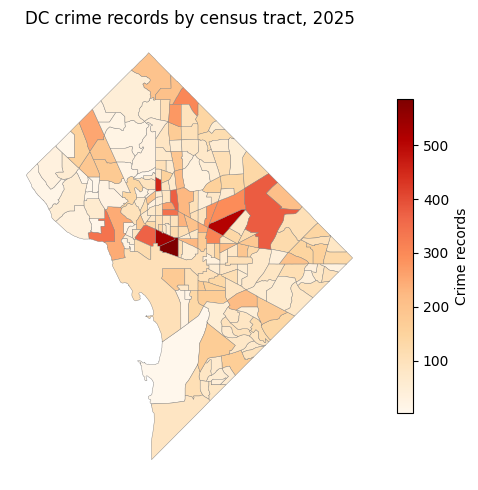

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))

tracts_with_crime.plot(
    column='crime_n',
    cmap='OrRd',
    edgecolor='grey',
    linewidth=0.3,
    legend=True,
    legend_kwds={'label': 'Crime records', 'shrink': 0.7},
    ax=ax
)

ax.set_title('DC crime records by census tract, 2025')
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 9. Save the result
The polygon shapefile contains the total count (`crime_n`) and the offense-type counts.
Share all generated shapefile companion files together. The CSV includes all these
attributes without polygon geometry.

In [ ]:
output_folder = Path('output/simple_4326')
output_folder.mkdir(parents=True, exist_ok=True)

# ADDED: shapefile field names are limited to 10 characters, so shorten the new columns explicitly
short_names = {
    'share_violent': 'shr_viol', 'share_gun': 'shr_gun', 'share_daytime': 'shr_day',
    'share_evening': 'shr_eve', 'share_midnight': 'shr_mid', 'share_weekend': 'shr_wknd',
    'alc_total_n': 'alc_n', 'bar_club_n': 'bar_n', 'restaurant_n': 'rest_n', 'entertain_n': 'ent_n',
    'dancing_n': 'dance_n', 'metro_entrance_n': 'metro_n', 'metro_station_n': 'station_n',
}
tracts_shp = tracts_with_crime.rename(columns=short_names)
too_long = [c for c in tracts_shp.columns if c != 'geometry' and len(c) > 10]
assert not too_long, f'shapefile names too long: {too_long}'

tracts_shp.to_file(                      # ALTERED: was tracts_with_crime.to_file(...)
    output_folder / 'dc_tracts_crime_2025.shp',
    driver='ESRI Shapefile',
    index=False
)

tracts_with_crime.drop(columns=['geometry']).to_csv(
    output_folder / 'dc_tract_crime_counts_2025.csv',
    index=False
)

# ADDED: Excel version of the full tract table (like our partner's tract_table.xlsx)
tracts_with_crime.drop(columns=['geometry']).to_excel(
    output_folder / 'dc_tract_table_2025.xlsx',
    index=False
)